In [1]:
import pandas as pd
import numpy as np

In [3]:
columns = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education_num",
    "marital_status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital_gain",
    "capital_loss",
    "hours_per_week",
    "native_country",
    "income"
]

In [5]:
train_df = pd.read_csv(
    "data/adult.data",
    names=columns,
    skipinitialspace=True
)

print(train_df.head())
print("Shape:", train_df.shape)

   age         workclass  fnlwgt  education  education_num  \
0   39         State-gov   77516  Bachelors             13   
1   50  Self-emp-not-inc   83311  Bachelors             13   
2   38           Private  215646    HS-grad              9   
3   53           Private  234721       11th              7   
4   28           Private  338409  Bachelors             13   

       marital_status         occupation   relationship   race     sex  \
0       Never-married       Adm-clerical  Not-in-family  White    Male   
1  Married-civ-spouse    Exec-managerial        Husband  White    Male   
2            Divorced  Handlers-cleaners  Not-in-family  White    Male   
3  Married-civ-spouse  Handlers-cleaners        Husband  Black    Male   
4  Married-civ-spouse     Prof-specialty           Wife  Black  Female   

   capital_gain  capital_loss  hours_per_week native_country income  
0          2174             0              40  United-States  <=50K  
1             0             0             

In [7]:
test_df = pd.read_csv(
    "data/adult.test",
    names=columns,
    skipinitialspace=True,
    skiprows=1
)

# Remove the trailing full stop from test labels
test_df["income"] = test_df["income"].str.rstrip(".")

print(test_df.head())
print("Shape:", test_df.shape)

   age  workclass  fnlwgt     education  education_num      marital_status  \
0   25    Private  226802          11th              7       Never-married   
1   38    Private   89814       HS-grad              9  Married-civ-spouse   
2   28  Local-gov  336951    Assoc-acdm             12  Married-civ-spouse   
3   44    Private  160323  Some-college             10  Married-civ-spouse   
4   18          ?  103497  Some-college             10       Never-married   

          occupation relationship   race     sex  capital_gain  capital_loss  \
0  Machine-op-inspct    Own-child  Black    Male             0             0   
1    Farming-fishing      Husband  White    Male             0             0   
2    Protective-serv      Husband  White    Male             0             0   
3  Machine-op-inspct      Husband  Black    Male          7688             0   
4                  ?    Own-child  White  Female             0             0   

   hours_per_week native_country income  
0       

In [9]:
print("Training records:", train_df.shape)
print("Testing records:", test_df.shape)

print("\nTraining income distribution:")
print(train_df["income"].value_counts())

print("\nMissing values:")
print(train_df.isin(["?"]).sum())

Training records: (32561, 15)
Testing records: (16281, 15)

Training income distribution:
income
<=50K    24720
>50K      7841
Name: count, dtype: int64

Missing values:
age                  0
workclass         1836
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     583
income               0
dtype: int64


In [11]:
# Replace '?' with NaN in both datasets

train_df = train_df.replace('?', np.nan)
test_df = test_df.replace('?', np.nan)

print("Training missing values:")
print(train_df.isnull().sum())

print("\nTesting missing values:")
print(test_df.isnull().sum())

Training missing values:
age                  0
workclass         1836
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     583
income               0
dtype: int64

Testing missing values:
age                 0
workclass         963
fnlwgt              0
education           0
education_num       0
marital_status      0
occupation        966
relationship        0
race                0
sex                 0
capital_gain        0
capital_loss        0
hours_per_week      0
native_country    274
income              0
dtype: int64


In [13]:
# check data types
print(train_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB
None


In [15]:
# Seperate input features and target

# Input features
X_train = train_df.drop('income', axis=1)

# Target variable
y_train = train_df['income']

# Test input features
X_test = test_df.drop('income', axis=1)

# Test target
y_test = test_df['income']

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (32561, 14)
X_test: (16281, 14)
y_train: (32561,)
y_test: (16281,)


In [19]:
# Identify Numerical and Categorical Columns (Features)
numeric_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

print("\nNumerical count:", len(numeric_features))
print("Categorical count:", len(categorical_features))

Numerical features: ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

Categorical features: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']

Numerical count: 6
Categorical count: 8


In [23]:
# Importing Preprocessing tools
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Create numerical transformation 
# Median imputation fills missing numerical values.
# StandardScaler brings numerical features to a comparable scale
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Create categorical transformation
# Missing categorical values are replaced with the most frequent category.
# OneHotEncoder converts text categories into numerical columns.
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combining both the pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [25]:
# Import Classification Algorithm
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

import time

# Define Five Models. Note LinearSVC is used for SVM
models = {

    "Logistic Regression":
        LogisticRegression(max_iter=1000),

    "Decision Tree":
        DecisionTreeClassifier(random_state=42),

    "KNN":
        KNeighborsClassifier(n_neighbors=5),

    "Naive Bayes":
        GaussianNB(),

    "SVM":
        LinearSVC(random_state=42, max_iter=5000)

}

print("Five classification models created!")

Five classification models created!


In [29]:
# Train all five models
# Combine the preprocessing pipeline with each classifier. 
# This ensures that every model receives identically preprocessed data.

from sklearn.pipeline import Pipeline

trained_models = {}

for name, model in models.items():

    print("Training:", name)

    # Combine preprocessing and classifier
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    start_time = time.time()

    # Train model
    pipeline.fit(X_train, y_train)

    end_time = time.time()

    trained_models[name] = pipeline

    print("Completed in",
          round(end_time - start_time, 2),
          "seconds\n")

print("All five models trained successfully!")

Training: Logistic Regression
Completed in 4.98 seconds

Training: Decision Tree
Completed in 0.92 seconds

Training: KNN
Completed in 0.2 seconds

Training: Naive Bayes
Completed in 0.28 seconds

Training: SVM
Completed in 0.86 seconds

All five models trained successfully!


In [35]:
# Evaluate the models and calculate six metrics
results = []

for name, pipeline in trained_models.items():

    # Predict income categories
    predictions = pipeline.predict(X_test)

    # Convert target to binary:
    # >50K = 1, <=50K = 0

    actual_binary = (y_test == '>50K').astype(int)
    predicted_binary = (predictions == '>50K').astype(int)

    # Calculate AUC using decision scores
    scores = pipeline.decision_function(X_test) \
        if name == "SVM" else pipeline.predict_proba(X_test)[:, 1]

    # Calculate metrics
    results.append({

        "Model": name,

        "Accuracy": accuracy_score(
            actual_binary, predicted_binary),

        "AUC": roc_auc_score(
            actual_binary, scores),

        "Precision": precision_score(
            actual_binary, predicted_binary),

        "Recall": recall_score(
            actual_binary, predicted_binary),

        "F1 Score": f1_score(
            actual_binary, predicted_binary),

        "MCC": matthews_corrcoef(
            actual_binary, predicted_binary)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy     AUC  Precision  Recall  F1 Score     MCC
0  Logistic Regression    0.8507  0.9038     0.7282  0.5871    0.6501  0.5618
1        Decision Tree    0.8127  0.7442     0.6013  0.6141    0.6077  0.4847
2                  KNN    0.8333  0.8564     0.6639  0.5962    0.6282  0.5224
3          Naive Bayes    0.5511  0.7611     0.3378  0.9376    0.4967  0.3300
4                  SVM    0.8518  0.9032     0.7373  0.5788    0.6485  0.5629


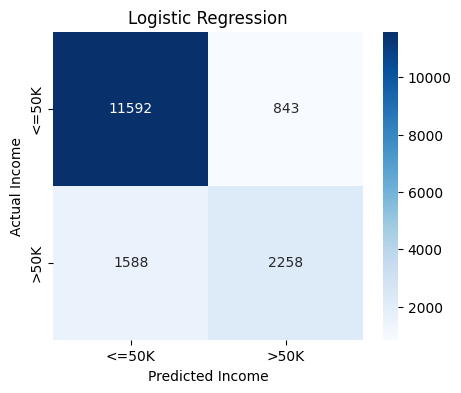

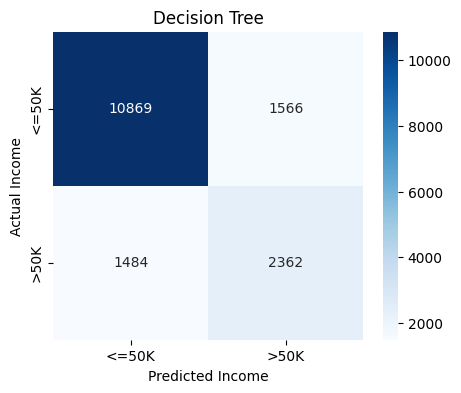

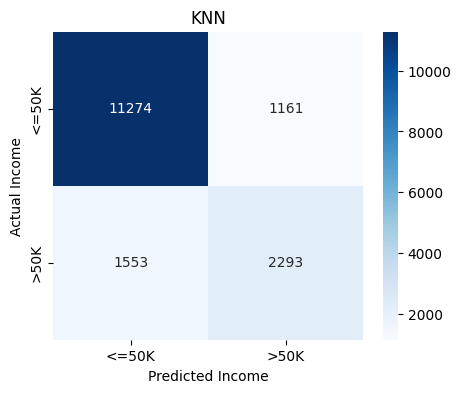

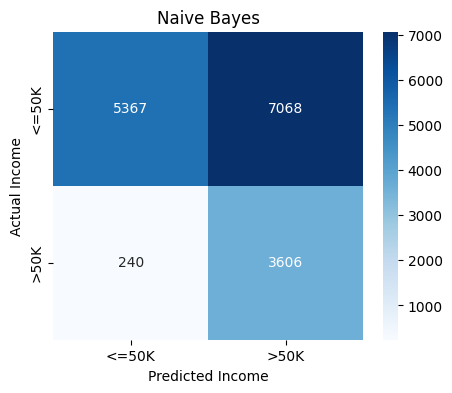

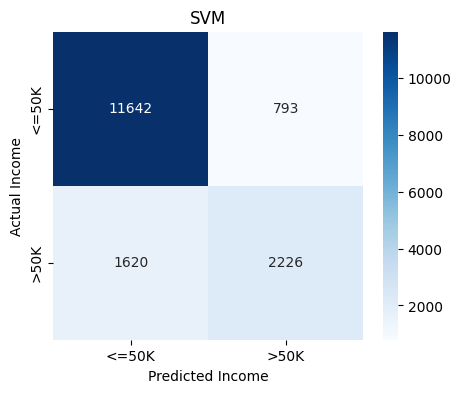

In [45]:
# Examine Confusion Metrics
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

for name, pipeline in trained_models.items():

    predictions = pipeline.predict(X_test)

    actual_binary = (y_test == '>50K').astype(int)
    predicted_binary = (predictions == '>50K').astype(int)

    cm = confusion_matrix(
        actual_binary,
        predicted_binary
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['<=50K', '>50K'],
        yticklabels=['<=50K', '>50K']
    )

    plt.title(name)
    plt.xlabel('Predicted Income')
    plt.ylabel('Actual Income')

    plt.show()

In [37]:
# Create a model directory
import os

# Create model directory
os.makedirs("model", exist_ok=True)

print("Model directory created successfully!")

# Save all five trained models
import joblib

for name, pipeline in trained_models.items():

    # Create filename
    filename = name.lower().replace(" ", "_") + ".joblib"

    # Save complete pipeline
    joblib.dump(
        pipeline,
        os.path.join("model", filename)
    )

    print("Saved:", filename)

print("\nAll five models saved successfully!")

Model directory created successfully!
Saved: logistic_regression.joblib
Saved: decision_tree.joblib
Saved: knn.joblib
Saved: naive_bayes.joblib
Saved: svm.joblib

All five models saved successfully!


In [39]:
# Verify save models
import joblib
import os

model_files = [
    "logistic_regression.joblib",
    "decision_tree.joblib",
    "knn.joblib",
    "naive_bayes.joblib",
    "svm.joblib"
]

loaded_models = {}

for filename in model_files:

    path = os.path.join("model", filename)

    loaded_models[filename] = joblib.load(path)

    print("Successfully loaded:", filename)

print("\nAll five models verified!")

# Test one prediction
# Load Logistic Regression
model = loaded_models["logistic_regression.joblib"]

# Predict first five test records
sample_predictions = model.predict(X_test.head(5))

print("Predicted income categories:")
print(sample_predictions)

print("\nActual income categories:")
print(y_test.head(5).values)

Successfully loaded: logistic_regression.joblib
Successfully loaded: decision_tree.joblib
Successfully loaded: knn.joblib
Successfully loaded: naive_bayes.joblib
Successfully loaded: svm.joblib

All five models verified!
Predicted income categories:
['<=50K' '<=50K' '<=50K' '>50K' '<=50K']

Actual income categories:
['<=50K' '<=50K' '>50K' '>50K' '<=50K']


In [41]:
# Creating test csv file
# Combine test features and actual target
test_data = X_test.copy()

test_data['income'] = y_test.values

# Save CSV
test_data.to_csv(
    "test_data.csv",
    index=False
)

print("Test dataset saved successfully!")
print("Shape:", test_data.shape)

Test dataset saved successfully!
Shape: (16281, 15)


In [43]:
# Verify
# Read the saved CSV
check_df = pd.read_csv("test_data.csv")

print("Dataset shape:", check_df.shape)

print("\nColumn names:")
print(check_df.columns.tolist())

print("\nFirst five records:")
print(check_df.head())

print("\nTarget distribution:")
print(check_df['income'].value_counts())

Dataset shape: (16281, 15)

Column names:
['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']

First five records:
   age  workclass  fnlwgt     education  education_num      marital_status  \
0   25    Private  226802          11th              7       Never-married   
1   38    Private   89814       HS-grad              9  Married-civ-spouse   
2   28  Local-gov  336951    Assoc-acdm             12  Married-civ-spouse   
3   44    Private  160323  Some-college             10  Married-civ-spouse   
4   18        NaN  103497  Some-college             10       Never-married   

          occupation relationship   race     sex  capital_gain  capital_loss  \
0  Machine-op-inspct    Own-child  Black    Male             0             0   
1    Farming-fishing      Husband  White    Male             0             0   
2    Protective-serv      